# Deterministic rectified flow

We chose a paired image-to-image flow, with **no random noise initialization**.
This notebook shows the training path and verifies the Euler solver using an
oracle velocity. The oracle has access to the target and is **not a learned model**.

Prerequisites: PyTorch, matplotlib, Warp, CUDA. Outline: render a pair, visualize
interpolation, inspect velocity, and verify the direction of integration.

In [1]:
from pathlib import Path
import sys
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "model.py").exists() and (p / "mandelbrot.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
assert torch.cuda.is_available(), "These notebooks use the CUDA renderer."
torch.manual_seed(20261016)
print(torch.cuda.get_device_name())
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11})

NVIDIA GeForce RTX 4090


In [2]:
from mandelbrot import ColorRenderer, View

SIZE = 128
AA = 8  # 8x8 subpixel samples (64 per pixel), averaged after coloring.
renderer = ColorRenderer(SIZE * AA, SIZE * AA)

def render_rgb(view):
    # ColorRenderer reuses buffers: clone before retaining a render.
    rgb = renderer.render(view).clone().permute(2, 0, 1)[None]
    return F.avg_pool2d(rgb, AA)

def zoom_pair(parent_view, left, top):
    side = SIZE // 4
    assert 0 <= left <= SIZE-side and 0 <= top <= SIZE-side
    parent = render_rgb(parent_view)
    crop = parent[:, :, top:top+side, left:left+side]
    coarse = F.interpolate(crop, size=(SIZE, SIZE), mode="bilinear", align_corners=False)
    # Positive image y points down; positive imaginary coordinates point up.
    offset = complex(left + side/2 - SIZE/2, SIZE/2 - top - side/2)
    center = parent_view.center + offset * parent_view.span / SIZE
    child_view = View(center=center, span=parent_view.span / 4,
                      iterations=parent_view.iterations)
    target = render_rgb(child_view)
    return parent, coarse, target, child_view

def show_rgb(axis, image, title):
    axis.imshow(image[0].detach().float().cpu().permute(1, 2, 0).clamp(0, 1), interpolation="nearest")
    axis.set_title(title)
    axis.axis("off")

Warp 1.18.0 initialized:
   CUDA Toolkit 13.4, Driver 13.0
   Devices:
     "cpu"      : "CPU"
     "cuda:0"   : "NVIDIA GeForce RTX 4090" (24 GiB, sm_89, mempool enabled)
   Kernel cache:
     /home/blacknoir/.cache/warp/1.18.0


In [3]:
_, coarse, target, child = zoom_pair(
    View(center=-.7435+.1314j, span=.012, iterations=8192), 48, 48)
y = coarse * 2 - 1
x = target * 2 - 1
print(f"Training image shape: {tuple(y.shape)}; target span: {child.span:g}")

Module mandelbrot 617f2d0 load on device 'cuda:0' took 0.32 ms  (cached)
Training image shape: (1, 3, 128, 128); target span: 0.003


## The supervised path

\[
z_t=(1-t)y+tx,\qquad u=x-y,\qquad
\mathcal L=\mathbb E\|v_\theta(z_t,t,y)-u\|^2.
\]

Here `t=0` is the coarse crop and `t=1` is the detailed target. The condition `y`
is fixed throughout integration. This convention differs from the repository's
earlier unconditional x-prediction experiment.

Reference: [Rectified Flow](https://arxiv.org/abs/2209.03003);
[FlowSR](https://arxiv.org/abs/2605.12377) provides an image-to-image SR precedent.
Our compact pixel-space model is an adaptation, not a reproduction of FlowSR.

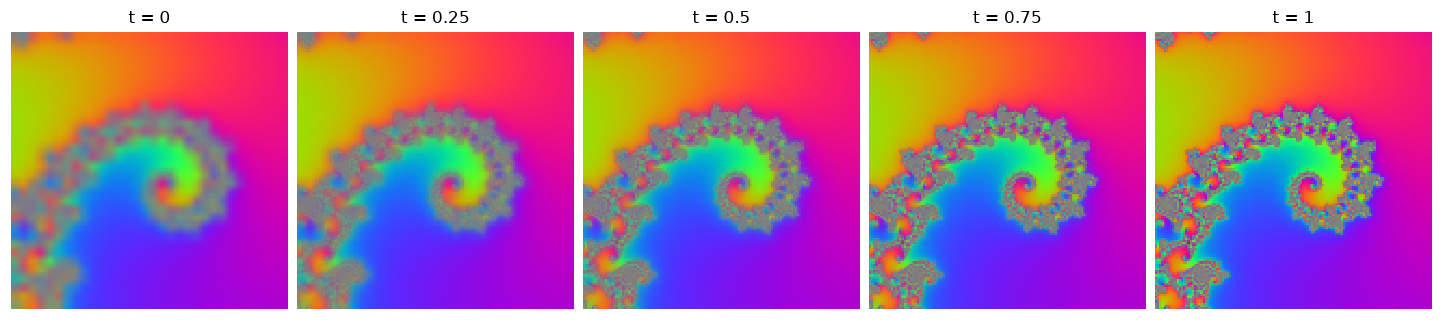

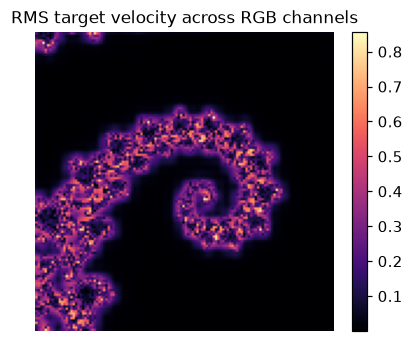

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3), constrained_layout=True)
for axis, t in zip(axes, (0., .25, .5, .75, 1.)):
    state = (1-t)*y + t*x
    show_rgb(axis, (state+1)/2, f"t = {t:g}")
plt.show()

fig, axis = plt.subplots(figsize=(4, 3), constrained_layout=True)
magnitude = (x-y).square().mean(dim=1).sqrt()[0]
plot = axis.imshow(magnitude.cpu(), cmap="magma")
axis.set_title("RMS target velocity across RGB channels")
axis.axis("off")
fig.colorbar(plot, ax=axis)
plt.show()

## Verify the actual repository solver

A constant oracle velocity reaches the endpoint in any positive number of
Euler steps, up to floating-point error. A learned field need not be constant
along its own trajectory, so this does **not** imply one-step learned sampling
will work. Ordinary straight-pair training is not a guarantee of straight ODE paths.

In [5]:
from torch import nn
from model import RectifiedFlow

class OracleVelocity(nn.Module):
    def forward(self, state, t, condition):
        return x - condition

oracle = OracleVelocity().cuda()
flow = RectifiedFlow()
print(f"Oracle velocity loss: {flow.loss(oracle, x, y).item():.8f}")
for steps in (1, 4, 16):
    prediction = flow.sample(oracle, y, steps=steps)
    error = (prediction-target).abs().max().item()
    print(f"{steps:2d} steps: maximum endpoint error {error:.3g}")
    torch.testing.assert_close(prediction, target, atol=2e-6, rtol=1e-5)

Oracle velocity loss: 0.00000000
 1 steps: maximum endpoint error 2.98e-08
 4 steps: maximum endpoint error 7.45e-08
16 steps: maximum endpoint error 2.53e-07


**Try:** reverse the velocity sign. Why does it move away from the target?
The check below compares one correct step and one step with the wrong sign.

An image-only input loses subpixel information. A deterministic model provides
one continuation per input; neither the objective nor a plausible image proves
that its detailed structures match the exact Mandelbrot viewport.

In [6]:
correct = y + (x-y)
wrong = y - (x-y)
print(f"Correct-sign endpoint MSE: {(correct-x).square().mean().item():.6g}")
print(f"Wrong-sign endpoint MSE:   {(wrong-x).square().mean().item():.6g}")

Correct-sign endpoint MSE: 2.89121e-19
Wrong-sign endpoint MSE:   0.113888
